# Member 4: Model Evaluation, Error Analysis & ROC-AUC Assessment
**Author:** IT24101748 — Evaluation & Recommendation  
**Winning Model:** Random Forest Classifier (Deep Tuned)  
**Dataset:** Untouched Test Set (`X_test_final.csv`, `y_test_final.csv` - 19,468 encounters, 86 features)  

---
### Objectives:
1. Perform a strict single-pass evaluation on the untouched test set (zero data leakage).
2. Compute multi-class metrics: **Precision, Recall, F1-Score, Overall Accuracy, and Multi-Class ROC-AUC (One-vs-Rest)**.
3. Generate a normalized **Confusion Matrix** to inspect prediction errors (False Positives vs False Negatives).
4. Plot **ROC-AUC Curves** and **Precision-Recall Curves** across all 3 classes (`NO`, `>30`, `<30`).
5. Save all evaluation metrics and visualizations for hospital reporting.

In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)
from sklearn.preprocessing import label_binarize

# Aesthetics
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'

os.makedirs('../results', exist_ok=True)
print('Imports and environment ready!')

Imports and environment ready!


In [2]:
# Load the untouched test set
X_test = pd.read_csv('../../dataset_processed/X_test_final.csv')
y_test = pd.read_csv('../../dataset_processed/y_test_final.csv').values.ravel()

# Load winning model from Member 3
model_path = '../../models/random_forest/random_forest_best_model.pkl'
model = joblib.load(model_path)

print(f'Test Data Loaded: {X_test.shape[0]:,} encounters, {X_test.shape[1]} features')
print(f'Loaded Best Model: {type(model).__name__}')

Test Data Loaded: 19,468 encounters, 86 features
Loaded Best Model: RandomForestClassifier


In [3]:
# Run single-pass test prediction
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)

class_labels = ['NO (0)', '>30 Days (1)', '<30 Days [High-Risk] (2)']
class_names = ['NO', '>30', '<30']

print('Inference completed successfully!')

Inference completed successfully!


In [4]:
report_dict = classification_report(y_test, y_pred, output_dict=True)
report_str = classification_report(y_test, y_pred, target_names=class_names, digits=4)

# Binarize labels for multi-class ROC-AUC (One-vs-Rest)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
roc_auc_macro = roc_auc_score(y_test_bin, y_proba, multi_class='ovr', average='macro')
roc_auc_weighted = roc_auc_score(y_test_bin, y_proba, multi_class='ovr', average='weighted')

print('=== UNTOUCHED TEST SET CLASSIFICATION REPORT ===')
print(report_str)
print(f'Macro ROC-AUC (OVR):    {roc_auc_macro:.4f}')
print(f'Weighted ROC-AUC (OVR): {roc_auc_weighted:.4f}')

# Save JSON summary
summary_metrics = {
    'test_samples': int(len(y_test)),
    'overall_accuracy': float(report_dict['accuracy']),
    'macro_f1': float(report_dict['macro avg']['f1-score']),
    'macro_recall': float(report_dict['macro avg']['recall']),
    'macro_precision': float(report_dict['macro avg']['precision']),
    'roc_auc_macro_ovr': float(roc_auc_macro),
    'minority_less30_recall': float(report_dict['2']['recall']),
    'minority_less30_precision': float(report_dict['2']['precision']),
    'minority_less30_f1': float(report_dict['2']['f1-score'])
}

with open('../results/test_metrics_summary.json', 'w') as f:
    json.dump(summary_metrics, f, indent=4)
print('Saved metrics summary to evaluation/results/test_metrics_summary.json')

=== UNTOUCHED TEST SET CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

          NO     0.6589    0.6557    0.6573     10292
         >30     0.4813    0.4580    0.4694      6919
         <30     0.2312    0.2707    0.2494      2257

    accuracy                         0.5408     19468
   macro avg     0.4571    0.4615    0.4587     19468
weighted avg     0.5462    0.5408    0.5432     19468

Macro ROC-AUC (OVR):    0.6668
Weighted ROC-AUC (OVR): 0.6714
Saved metrics summary to evaluation/results/test_metrics_summary.json


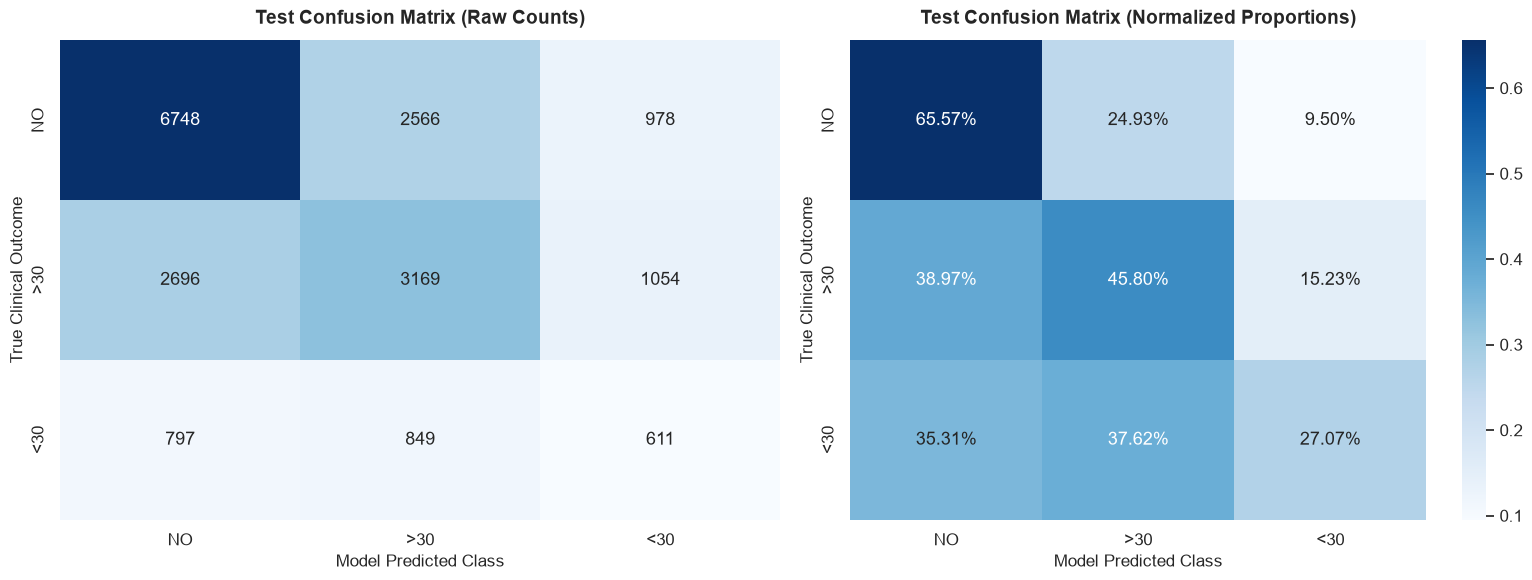

In [5]:
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Raw counts
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=class_names, yticklabels=class_names, cbar=False)
axes[0].set_title('Test Confusion Matrix (Raw Counts)', fontsize=14, fontweight='bold', pad=12)
axes[0].set_ylabel('True Clinical Outcome', fontsize=12)
axes[0].set_xlabel('Model Predicted Class', fontsize=12)

# Normalized proportions
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues', ax=axes[1],
            xticklabels=class_names, yticklabels=class_names)
axes[1].set_title('Test Confusion Matrix (Normalized Proportions)', fontsize=14, fontweight='bold', pad=12)
axes[1].set_ylabel('True Clinical Outcome', fontsize=12)
axes[1].set_xlabel('Model Predicted Class', fontsize=12)

plt.tight_layout()
plt.savefig('../results/confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

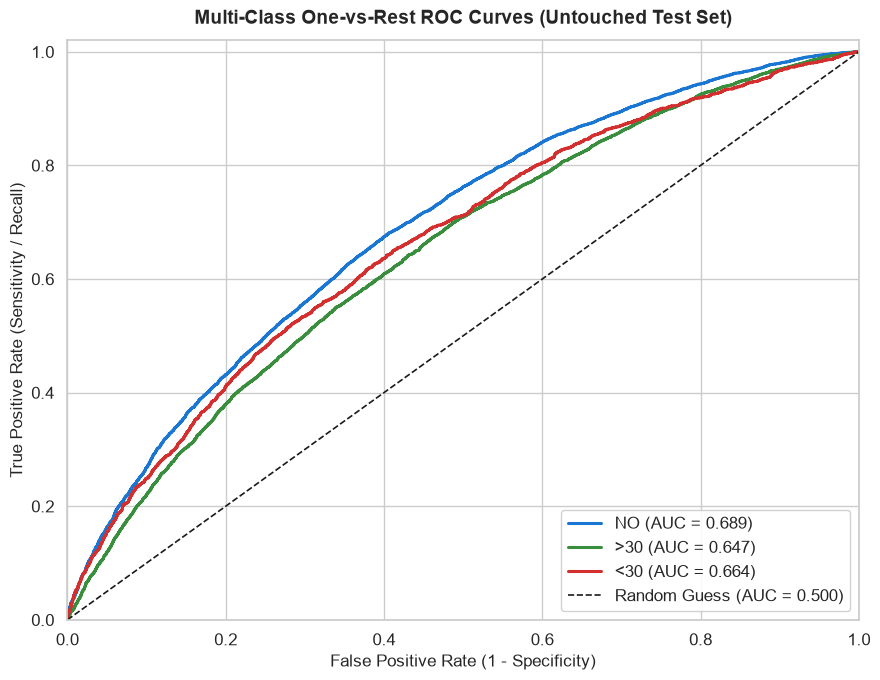

In [6]:
plt.figure(figsize=(9, 7))
colors = ['#1976d2', '#388e3c', '#d32f2f']

for i, (name, col) in enumerate(zip(class_names, colors)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    auc_score = roc_auc_score(y_test_bin[:, i], y_proba[:, i])
    plt.plot(fpr, tpr, color=col, lw=2.2, label=f'{name} (AUC = {auc_score:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.2, label='Random Guess (AUC = 0.500)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.02])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12)
plt.title('Multi-Class One-vs-Rest ROC Curves (Untouched Test Set)', fontsize=14, fontweight='bold', pad=12)
plt.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.savefig('../results/multiclass_roc_auc_curves.png', dpi=300, bbox_inches='tight')
plt.show()

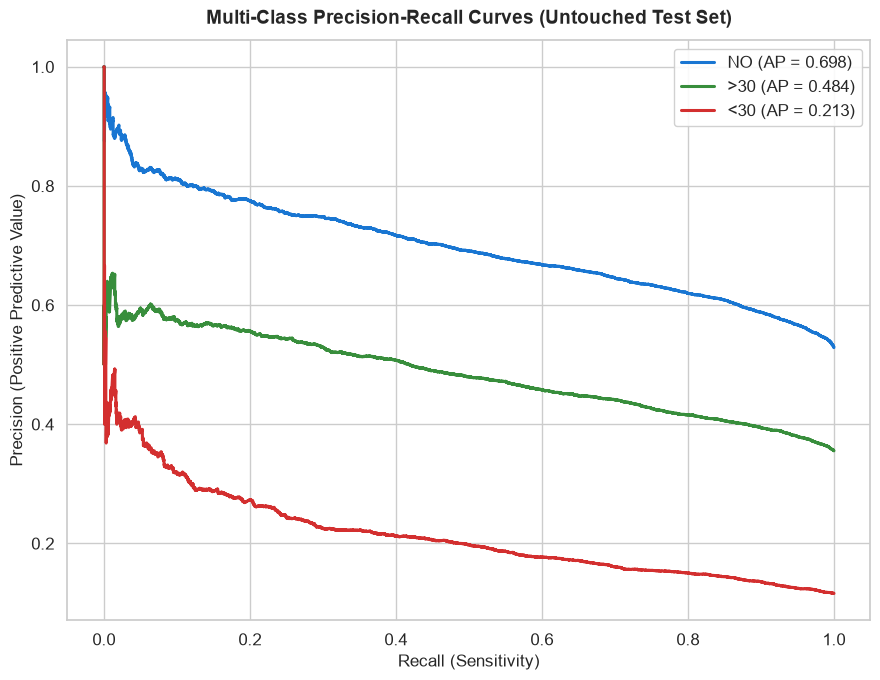

In [7]:
plt.figure(figsize=(9, 7))

for i, (name, col) in enumerate(zip(class_names, colors)):
    precision, recall, _ = precision_recall_curve(y_test_bin[:, i], y_proba[:, i])
    ap = average_precision_score(y_test_bin[:, i], y_proba[:, i])
    plt.plot(recall, precision, color=col, lw=2.2, label=f'{name} (AP = {ap:.3f})')

plt.xlabel('Recall (Sensitivity)', fontsize=12)
plt.ylabel('Precision (Positive Predictive Value)', fontsize=12)
plt.title('Multi-Class Precision-Recall Curves (Untouched Test Set)', fontsize=14, fontweight='bold', pad=12)
plt.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.savefig('../results/multiclass_pr_curves.png', dpi=300, bbox_inches='tight')
plt.show()